<a href="https://colab.research.google.com/github/mo-gaafar/CGM_Prediction_LSTM/blob/main/src/main.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [10]:
# ===============================================
# 🚀 GOOGLE COLAB SETUP (RUN THIS FIRST!)
# ===============================================

try:
    import google.colab
    IN_COLAB = True
    print("🔥 Running on Google Colab!")

    # Mount Google Drive
    from google.colab import drive
    drive.mount('/content/drive')
    print("✅ Google Drive mounted successfully!")

    # Install required packages
    print("📦 Installing required packages...")
    !pip install xgboost==1.7.0 imbalanced-learn scikit-learn pandas numpy matplotlib seaborn --quiet
    print("✅ All packages installed!")

    # Set data path for Colab
    DATA_PATH = '/content/drive/MyDrive/Colab Notebooks/BRFSS_2023.csv'
    print(f"📂 Data path set to: {DATA_PATH}")

    # Enable GPU if available
    import torch
    if torch.cuda.is_available():
        print("⚡ GPU is available for acceleration!")
    else:
        print("💻 Running on CPU (consider enabling GPU in Runtime > Change runtime type)")

except ImportError:
    IN_COLAB = False
    print("💻 Running locally (not in Colab)")
    DATA_PATH = "../data/BRFSS_2023.csv"  # Local path

print("\n🎯 Setup complete! Ready to start analysis.")
print("" + "="*50)

🔥 Running on Google Colab!
Mounted at /content/drive
✅ Google Drive mounted successfully!
📦 Installing required packages...
ERROR: Could not find a version that satisfies the requirement xgboost==1.7.0 (from versions: 0.4a12, 0.4a13, 0.4a14, 0.4a15, 0.4a18, 0.4a19, 0.4a20, 0.4a21, 0.4a22, 0.4a23, 0.4a24, 0.4a25, 0.4a26, 0.4a27, 0.4a28, 0.4a29, 0.4a30, 0.6a1, 0.6a2, 0.7.post3, 0.7.post4, 0.71, 0.72.1, 0.80, 0.81, 0.82, 0.90, 1.0.0rc2, 1.0.0, 1.0.1, 1.0.2, 1.1.0rc1, 1.1.0rc2, 1.1.0, 1.1.1, 1.2.0rc2, 1.2.0, 1.2.1rc1, 1.2.1, 1.3.0rc1, 1.3.0.post0, 1.3.1, 1.3.2, 1.3.3, 1.4.0rc1, 1.4.0, 1.4.1, 1.4.2, 1.5.0rc1, 1.5.0, 1.5.1, 1.5.2, 1.6.0rc1, 1.6.0, 1.6.1, 1.6.2, 1.7.0.post0, 1.7.1, 1.7.2, 1.7.3, 1.7.4, 1.7.5, 1.7.6, 2.0.0rc1, 2.0.0, 2.0.1, 2.0.2, 2.0.3, 2.1.0rc1, 2.1.0, 2.1.1, 2.1.2, 2.1.3, 2.1.4, 3.0.0rc1, 3.0.0, 3.0.1, 3.0.2)
ERROR: No matching distribution found for xgboost==1.7.0
✅ All packages installed!
📂 Data path set to: /content/drive/MyDrive/Colab Notebooks/BRFSS_2023.csv
⚡ GPU is a

In [11]:
import os
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
# pipline
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from imblearn.under_sampling import RandomUnderSampler
from imblearn.over_sampling import SMOTE

# Heart Disease Classification - Google Colab

This notebook is optimized for Google Colab with free GPU acceleration.

## Quick Setup Instructions:
1. Upload the BRFSS_2023.csv file to your Google Drive
2. Run the setup cell below to mount Google Drive
3. The notebook will automatically install all required packages
4. Enjoy faster training with GPU acceleration!

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/your-username/heart-disease-classification/blob/main/src/main.ipynb)

You will need to load the dataset before you can use it. This can be done by running the following command:

```bash
python -m src.load_dataset
```

In [12]:
# ===============================================
# 📂 LOAD DATASET
# ===============================================

import time
start_time = time.time()

try:
    # Try the path set in the setup cell
    df = pd.read_csv(DATA_PATH)
    print(f"✅ Data loaded successfully from {DATA_PATH}")
except FileNotFoundError:
    # Fallback paths for different environments
    print("🔍 Trying fallback paths...")
    fallback_paths = [
        "../data/BRFSS_2023.csv",  # Local
        "data/BRFSS_2023.csv",     # Alternative local
        "BRFSS_2023.csv",          # Same directory
        "/content/BRFSS_2023.csv", # Colab alternative
    ]

    df = None
    for path in fallback_paths:
        try:
            df = pd.read_csv(path)
            print(f"✅ Data loaded from fallback path: {path}")
            break
        except FileNotFoundError:
            continue

    if df is None:
        print("❌ Could not find BRFSS_2023.csv in any location.")
        print("\n📝 INSTRUCTIONS:")
        print("1. Download BRFSS_2023.csv from: https://www.cdc.gov/brfss/annual_data/annual_2023.html")
        print("2. Upload it to your Google Drive root folder (for Colab)")
        print("3. Or place it in the data/ folder (for local execution)")
        raise FileNotFoundError("퉴c Dataset not found!")

load_time = time.time() - start_time
print(f"\n⏱️  Loading time: {load_time:.2f} seconds")
print(f"📄 Dataset shape: {df.shape}")
print(f"💾 Memory usage: {df.memory_usage().sum() / (1024**2):.1f} MB")
print("" + "="*50)

✅ Data loaded successfully from /content/drive/MyDrive/Colab Notebooks/BRFSS_2023.csv

⏱️  Loading time: 0.64 seconds
📄 Dataset shape: (7289, 345)
💾 Memory usage: 19.2 MB


In [15]:
df.head()

,_STATE,FMONTH,IDATE,IMONTH,IDAY,IYEAR,DISPCODE,SEQNO,_PSU,CTELENM1,...,DROCDY4_,_RFBING6,_DRNKWK2,_RFDRHV8,_FLSHOT7,_PNEUMO3,_AIDTST4,_RFSEAT2,_RFSEAT3,_DRNKDRV
0,1,1,3012023,3,1,2023,1100,2023000001,2023000001,1.0,...,0.0,1.0,0.0,1.0,2.0,2.0,2.0,1.0,1.0,9.0
1,1,1,1062023,1,6,2023,1100,2023000002,2023000002,1.0,...,0.0,1.0,0.0,1.0,1.0,1.0,2.0,1.0,1.0,9.0
2,1,1,3082023,3,8,2023,1100,2023000003,2023000003,1.0,...,0.0,1.0,0.0,1.0,1.0,1.0,2.0,1.0,1.0,9.0
3,1,1,3062023,3,6,2023,1100,2023000004,2023000004,1.0,...,0.0,1.0,0.0,1.0,1.0,1.0,1.0,1.0,1.0,9.0
4,1,1,1062023,1,6,2023,1100,2023000005,2023000005,1.0,...,7.0,1.0,47.0,1.0,2.0,1.0,2.0,1.0,1.0,2.0


In [16]:
df.shape

(7289, 345)

### Initial Data Inspection

Inspect missing values

In [17]:
df.isnull().sum().sort_values(ascending=False)

,0
ACEDRINK,7289
ACETTHEM,7289
ACEHVSEX,7289
ACEADSAF,7289
ACETOUCH,7289
...,...
CVDCRHD4,0
RENTHOM1,0
_WT2RAKE,0
_STATE,0


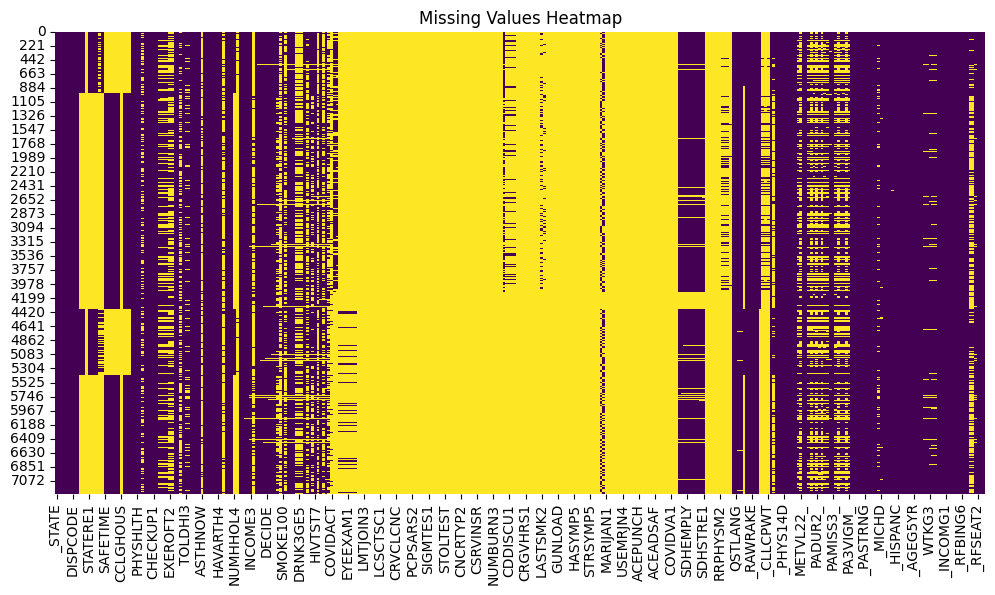

In [18]:
# visualize missing values
plt.figure(figsize=(12, 6))
sns.heatmap(df.isnull(), cbar=False, cmap='viridis')
plt.title("Missing Values Heatmap")
plt.show()

Age Distribution

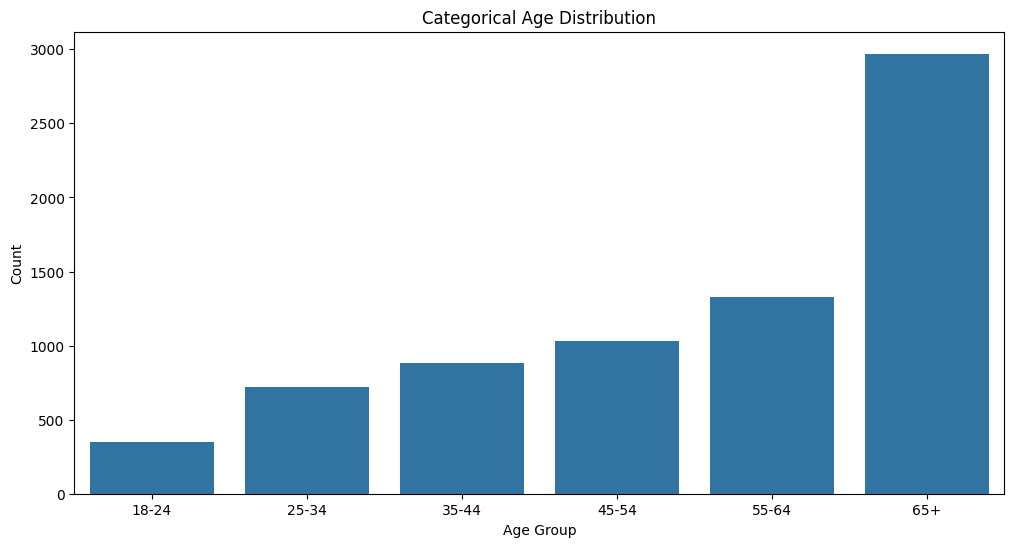

In [19]:
age_labels = {
    1: '18-24',
    2: '25-34',
    3: '35-44',
    4: '45-54',
    5: '55-64',
    6: '65+'
}
plt.figure(figsize=(12, 6))
sns.countplot(x='_AGE_G', data=df)
plt.title('Categorical Age Distribution')
plt.xlabel('Age Group')
plt.ylabel('Count')
plt.xticks(ticks=range(6), labels=age_labels.values())
plt.show()

Target Variable Distribution

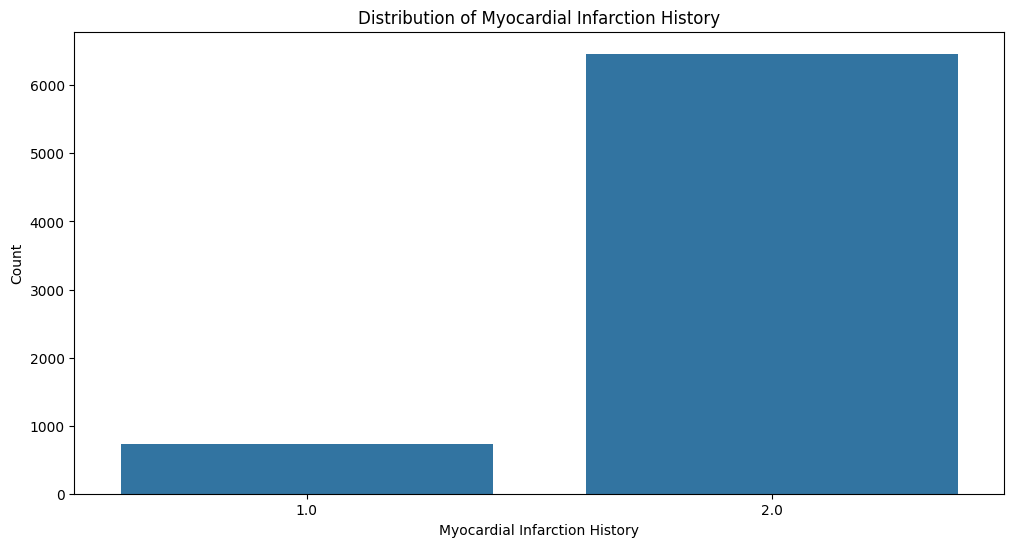

In [20]:
# _MICHD distribution
plt.figure(figsize=(12, 6))
sns.countplot(x='_MICHD', data=df)
plt.title('Distribution of Myocardial Infarction History')
plt.xlabel('Myocardial Infarction History')
plt.ylabel('Count')
plt.show()

In [21]:
df['_MICHD'].value_counts(normalize=True)


,proportion
_MICHD,
2.0,0.898402
1.0,0.101598


### Data Preprocessing & Feature Selection

Drop features with too many missing values. These were likely hidden to comply with new privacy regulations.

In [22]:
# Drop columns with more than 30% missing
threshold = 0.7
missing_fraction = df.isnull().mean()
cols_to_drop = missing_fraction[missing_fraction > threshold].index
df.drop(columns=cols_to_drop, inplace=True)
print(f"Dropped {len(cols_to_drop)} columns with >70% missing values.")

Dropped 154 columns with >70% missing values.


Inspect remaining columns

In [23]:
remaining_columns = df.columns.tolist()
print(f"Remaining columns after dropping: {remaining_columns}")

Remaining columns after dropping: ['_STATE', 'FMONTH', 'IDATE', 'IMONTH', 'IDAY', 'IYEAR', 'DISPCODE', 'SEQNO', '_PSU', 'SAFETIME', 'CTELNUM1', 'CELLFON5', 'CADULT1', 'CELLSEX2', 'PVTRESD3', 'CSTATE1', 'LANDLINE', 'HHADULT', 'SEXVAR', 'GENHLTH', 'PHYSHLTH', 'MENTHLTH', 'POORHLTH', 'PRIMINS1', 'PERSDOC3', 'MEDCOST1', 'CHECKUP1', 'EXERANY2', 'EXRACT12', 'EXEROFT1', 'EXERHMM1', 'EXRACT22', 'EXEROFT2', 'EXERHMM2', 'STRENGTH', 'BPHIGH6', 'BPMEDS1', 'CHOLCHK3', 'TOLDHI3', 'CHOLMED3', 'CVDINFR4', 'CVDCRHD4', 'CVDSTRK3', 'ASTHMA3', 'CHCSCNC1', 'CHCOCNC1', 'CHCCOPD3', 'ADDEPEV3', 'CHCKDNY2', 'HAVARTH4', 'DIABETE4', 'MARITAL', 'EDUCA', 'RENTHOM1', 'CPDEMO1C', 'VETERAN3', 'EMPLOY1', 'CHILDREN', 'INCOME3', 'WEIGHT2', 'HEIGHT3', 'DEAF', 'BLIND', 'DECIDE', 'DIFFWALK', 'DIFFDRES', 'DIFFALON', 'FALL12MN', 'SMOKE100', 'SMOKDAY2', 'USENOW3', 'ECIGNOW2', 'ALCDAY4', 'AVEDRNK3', 'DRNK3GE5', 'MAXDRNKS', 'FLUSHOT7', 'FLSHTMY3', 'PNEUVAC4', 'SHINGLE2', 'HIVTST7', 'HIVTSTD3', 'SEATBELT', 'DRNKDRI2', 'COVIDPO1'

Selected features based on domain knowledge and data exploration.

In [24]:
filtered_features = [
    "GENHLTH", # "_RFHLTH",
    "PHYSHLTH", # "_PHYS14D",
    "MENTHLTH", # "_MENT14D",
    "_HLTHPL1",
    "_PACAT3",
    "_RFHYPE6",
    "_RFCHOL3",
    "_LTASTH1",
    "ADDEPEV3",
    "CHCKDNY2",
    "DIABETE4",
    "CVDSTRK3",
    "_SEX",
    "_AGE_G",
    "_BMI5CAT", # "_RFBMI5", "_BMI5",
    "_INCOMG1",
    "_RACEPRV",
    "_METSTAT",
    "_SMOKER3",
    "_RFDRHV8",
    "_MICHD", #! Target variable
]

# Filter the DataFrame to keep only selected features
df_filtered = df[filtered_features].copy()


Inspect feature values

In [25]:
# unique values in the filtered DataFrame
print("Unique values in filtered DataFrame:")
for col in df_filtered.columns:
    print(f"{col}: {df_filtered[col].unique()}")

Unique values in filtered DataFrame:
GENHLTH: [2. 4. 3. 5. 1. 7. 9.]
PHYSHLTH: [88.  6.  2.  8.  1.  5.  4. 30. 15. 21. 10. 25. 14.  7. 20. 77.  3. 12.
 26.  9. 24. 18. 13. 99. 28. 23. 16. 17. 11. 29. 27. 22. 19.]
MENTHLTH: [88.  2.  3. 77. 10. 25.  5. 30. 20. 15. 12.  4.  1.  6. 21. 14.  7. 99.
 29.  8. 18. 16. 17.  9. 28. 13. 22. 11. 24. 27. 23.]
_HLTHPL1: [1 2 9]
_PACAT3: [ 4.  1.  9.  2.  3. nan]
_RFHYPE6: [ 2.  1.  9. nan]
_RFCHOL3: [ 1.  2. nan  9.]
_LTASTH1: [ 1.  2.  9. nan]
ADDEPEV3: [2. 1. 7. 9.]
CHCKDNY2: [2. 1. 7. 9.]
DIABETE4: [1. 3. 2. 7. 4. 9.]
CVDSTRK3: [2. 1. 7. 9.]
_SEX: [ 2.  1. nan]
_AGE_G: [ 6.  5.  4.  3.  2.  1. nan]
_BMI5CAT: [ 4.  3.  2. nan  1.]
_INCOMG1: [ 9.  1.  5.  4.  6.  2.  3.  7. nan]
_RACEPRV: [ 1.  2.  6.  3.  7.  4.  8.  5. nan]
_METSTAT: [ 1.  2. nan]
_SMOKER3: [ 4.  3.  1.  9.  2. nan]
_RFDRHV8: [ 1.  9.  2. nan]
_MICHD: [ 2.  1. nan]


Label encoding

In [26]:
remappings = {
    "GENHLTH": {1: 5, 2: 4, 3: 3, 4: 2, 5: 1, 7: np.nan, 9: np.nan},
    "PHYSHLTH": {88: 0, 77: np.nan, 99: np.nan},
    "MENTHLTH": {88: 0, 77: np.nan, 99: np.nan},
    "_HLTHPL1": {2: 0, 9: np.nan},
    "_PACAT3": {4: 0, 3: 1, 1: 3, 9: np.nan},
    "_RFHYPE6": {1: 0, 2: 1, 9: np.nan},
    "_RFCHOL3": {1: 0, 2: 1, 9: np.nan},
    "_LTASTH1": {1: 0, 2: 1, 9: np.nan},
    "ADDEPEV3": {2: 0, 7: np.nan, 9: np.nan},
    "CHCKDNY2": {2: 0, 7: np.nan, 9: np.nan},
    "DIABETE4": {2: 1, 3: 0, 4: 0, 7: np.nan, 9: np.nan},
    "CVDSTRK3": {2: 0, 7: np.nan, 9: np.nan},
    "_INCOMG1": {9: np.nan},
    "_METSTAT": {2: 0},
    "_SMOKER3": {4: 0, 3: 1, 1: 3, 9: np.nan},
    "_RFDRHV8": {1: 0, 2: 1, 9: np.nan},
    "_MICHD": {2: 0}
}

for col, mapping in remappings.items():
    df_filtered[col] = df_filtered[col].replace(mapping)

Convert columns to categorical/ordinal as needed

In [27]:
categorical_cols = ['_HLTHPL1', '_RFHYPE6', '_RFCHOL3', '_LTASTH1', 'ADDEPEV3', 'CHCKDNY2', 'DIABETE4', 'CVDSTRK3', '_SEX', '_RACEPRV', '_METSTAT', '_SMOKER3', '_RFDRHV8', '_MICHD']
ordinal_cols = {
    'GENHLTH': [1, 2, 3, 4, 5],
    '_PACAT3': [0, 1, 2, 3],
    '_AGE_G': [1, 2, 3, 4, 5, 6],
    '_BMI5CAT': [1, 2, 3, 4],
    '_INCOMG1': [1, 2, 3, 4, 5, 6],
}

for col in categorical_cols:
    df_filtered[col] = df_filtered[col].astype("category")

for col, order in ordinal_cols.items():
    df_filtered[col] = pd.Categorical(df_filtered[col], categories=order, ordered=True)

Rename columns for clarity

In [28]:
rename_map = {
    'PHYSHLTH': 'PHYUNHLTHY_',
    'MENTHLTH': 'MENTUNHLTHY_',
    '_HLTHPL1': 'INSURED',
    '_PACAT3': 'PHYSACT',
    '_RFHYPE6': 'HYPRTNSN',
    '_RFCHOL3': 'CHOLSTRL',
    '_LTASTH1': 'ASTHMA',
    'ADDEPEV3': 'DEPRSN',
    'CHCKDNY2': 'KDNY',
    'DIABETE4': 'DIABETIC',
    'CVDSTRK3': 'STROKE',
    '_SEX': 'SEX',
    '_AGE_G': 'AGE',
    '_BMI5CAT': 'BMI_CAT',
    '_INCOMG1': 'INCOME',
    '_RACEPRV': 'RACE',
    '_METSTAT': 'MTRPLTN',
    '_SMOKER3': 'SMOKING',
    '_RFDRHV8': 'DRNKHEAVY',
    '_MICHD': 'CHD_MI'
}

for old_name, new_name in rename_map.items():
    df_filtered.rename(columns={old_name: new_name}, inplace=True)

##### Missing Data Imputation

In [29]:
df_filtered.isnull().sum().sort_values(ascending=False)

,0
INCOME,1858
PHYSACT,1462
CHOLSTRL,956
BMI_CAT,531
DRNKHEAVY,379
SMOKING,254
INSURED,213
PHYUNHLTHY_,180
MENTUNHLTHY_,130
CHD_MI,94


Drop/impute missing values

In [30]:
# Drop rows where the target is missing
df_filtered = df_filtered.dropna(subset=['CHD_MI'])

# List of categorical features to impute with mode (most frequent)
mode_impute_cols = ['GENHLTH', 'INSURED', 'PHYSACT', 'HYPRTNSN', 'CHOLSTRL', 'ASTHMA', 'DEPRSN', 'KDNY', 'DIABETIC', 'STROKE', 'BMI_CAT', 'INCOME', 'RACE', 'MTRPLTN', 'SMOKING', 'DRNKHEAVY', 'CHD_MI']

for col in mode_impute_cols:
    df_filtered[col] = df_filtered[col].fillna(df_filtered[col].mode()[0])

# List of numerical columns — fill with median
median_impute_cols = ['PHYUNHLTHY_', 'MENTUNHLTHY_']

for col in median_impute_cols:
    df_filtered[col] = df_filtered[col].fillna(df_filtered[col].median())

<ipython-input-30-1823f3220cda>:8: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_filtered[col] = df_filtered[col].fillna(df_filtered[col].mode()[0])
<ipython-input-30-1823f3220cda>:14: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_filtered[col] = df_filtered[col].fillna(df_filtered[col].median())


### Data Exploration

In [31]:
df_filtered.describe(include='all').T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
GENHLTH,7195.0,5.0,3.0,2508.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
PHYUNHLTHY_,7195.0,NaN,NaN,NaN,4.623628,8.997117,0.0,0.0,0.0,4.0,30.0
MENTUNHLTHY_,7195.0,NaN,NaN,NaN,4.135233,8.271789,0.0,0.0,0.0,3.0,30.0
INSURED,7195.0,2.0,1.0,6833.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
PHYSACT,7195.0,4.0,3.0,3871.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
HYPRTNSN,7195.0,2.0,0.0,3762.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
CHOLSTRL,7195.0,2.0,0.0,4305.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
ASTHMA,7195.0,2.0,0.0,6180.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
DEPRSN,7195.0,2.0,0.0,5742.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
KDNY,7195.0,2.0,0.0,6848.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN


#### Visualizations

Age-Target Relationship and Distribution

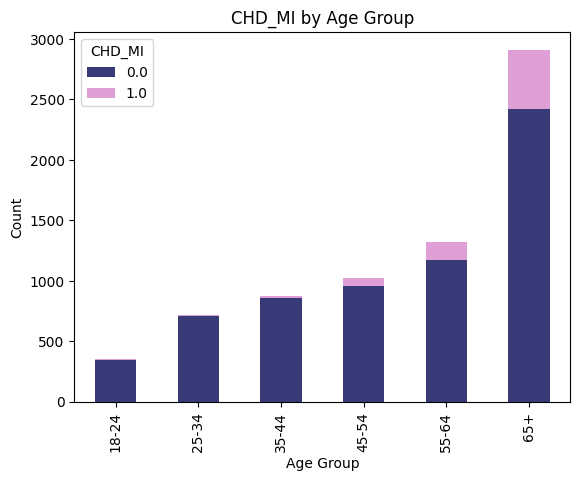

In [32]:

age_labels = {
    1: '18-24',
    2: '25-34',
    3: '35-44',
    4: '45-54',
    5: '55-64',
    6: '65+'
}

# RELATION BETWEEN AGE AND CHD_MI
crosstab_age_chd = pd.crosstab(df_filtered['AGE'], df_filtered['CHD_MI'])
crosstab_age_chd.plot(kind='bar', stacked=True, cmap='tab20b')
plt.title("CHD_MI by Age Group")
plt.xlabel("Age Group")
plt.ylabel("Count")
plt.xticks(ticks=range(len(age_labels)), labels=age_labels.values())
plt.show()


Sex Distribution

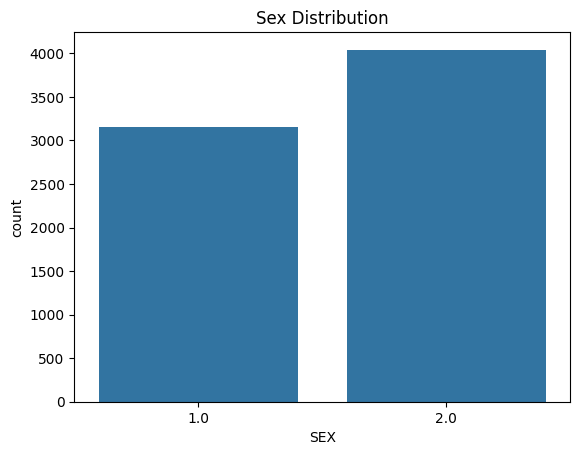

In [33]:

sns.countplot(x="SEX", data=df_filtered)
plt.title("Sex Distribution")
plt.show()


Unhealthy physical and mental days distribution

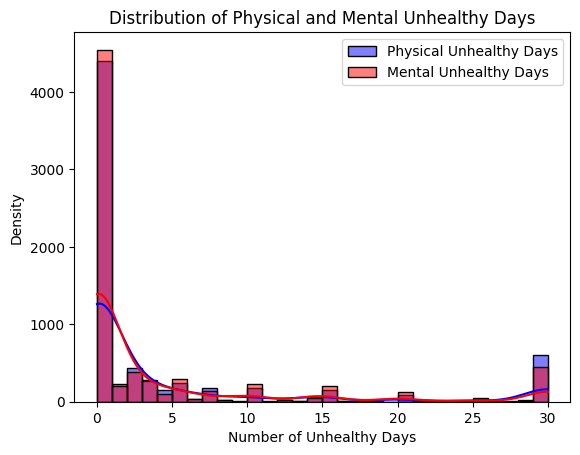

In [34]:
# continuous physical and mental health days on same plot
sns.histplot(df_filtered['PHYUNHLTHY_'], bins=30, kde=True, label='Physical Unhealthy Days', color='blue')
sns.histplot(df_filtered['MENTUNHLTHY_'], bins=30, kde=True, label='Mental Unhealthy Days', color='red', alpha=0.5)
plt.title('Distribution of Physical and Mental Unhealthy Days')
plt.xlabel('Number of Unhealthy Days')
plt.ylabel('Density')
plt.legend()
plt.show()

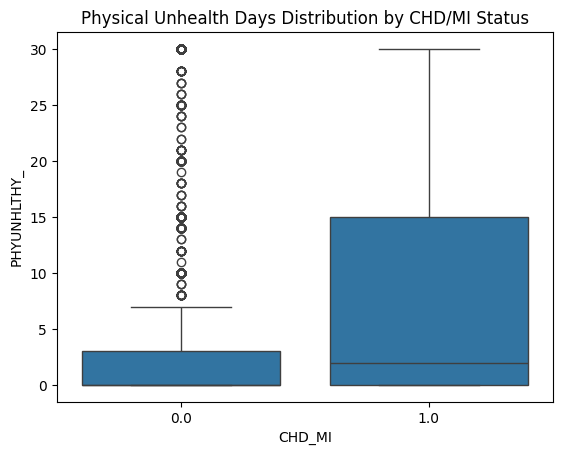

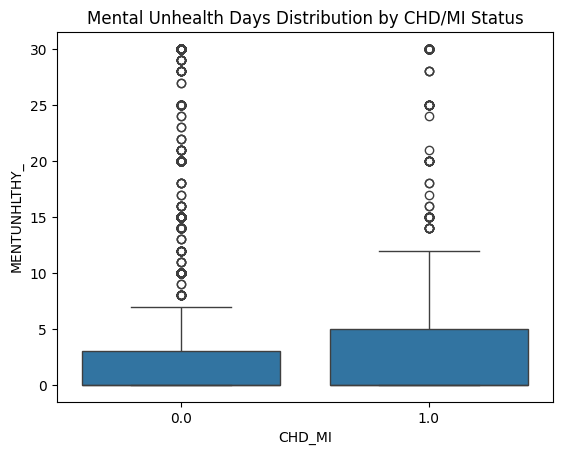

In [35]:
sns.boxplot(x="CHD_MI", y="PHYUNHLTHY_", data=df_filtered)
plt.title("Physical Unhealth Days Distribution by CHD/MI Status")
plt.show()

sns.boxplot(x="CHD_MI", y="MENTUNHLTHY_", data=df_filtered)
plt.title("Mental Unhealth Days Distribution by CHD/MI Status")
plt.show()

Categorical feature-target relations

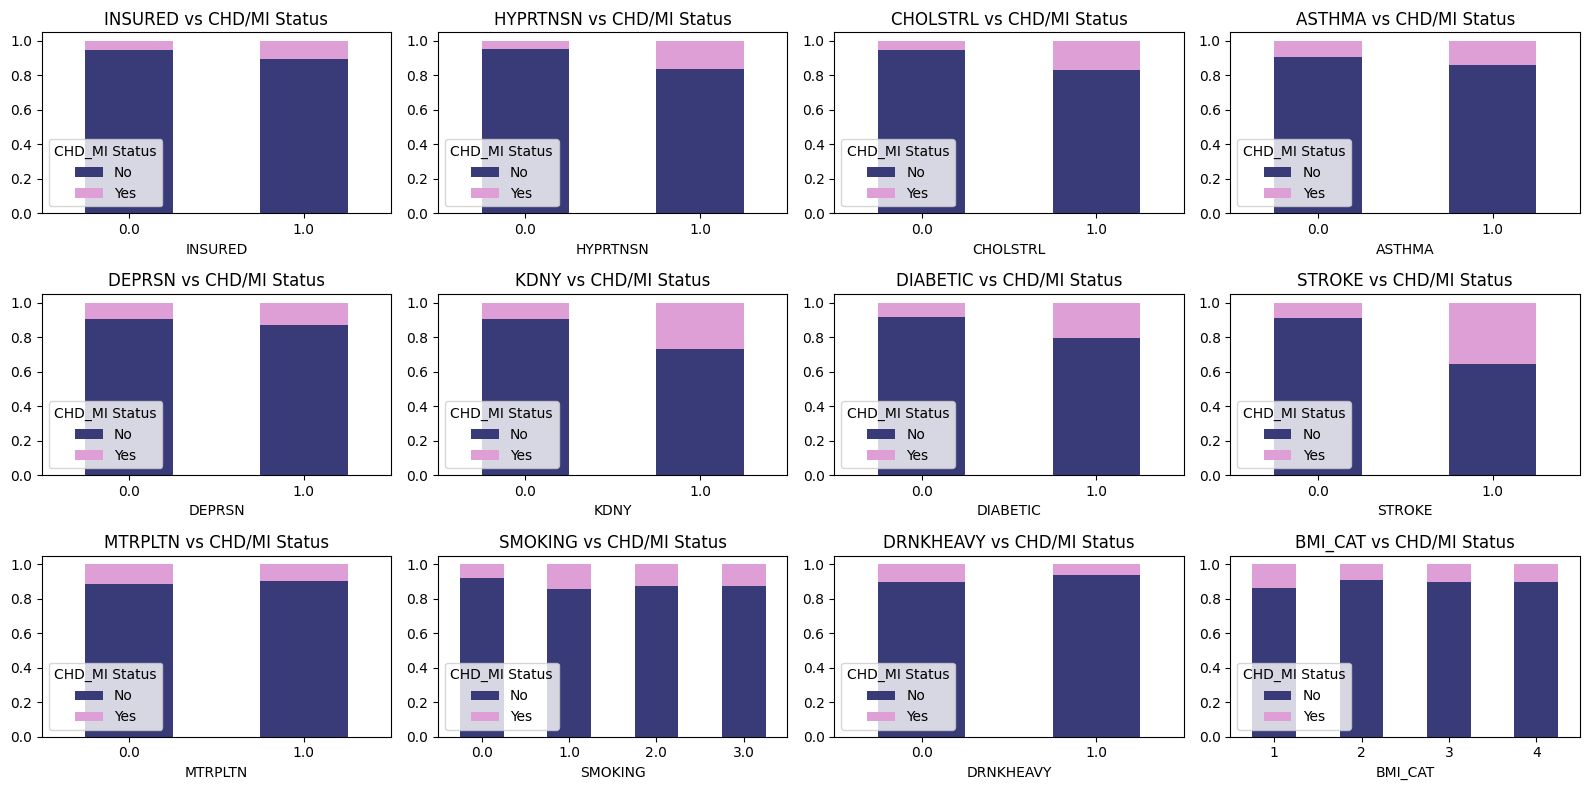

In [36]:
features = [
    'INSURED', 'HYPRTNSN', 'CHOLSTRL', 'ASTHMA',
    'DEPRSN', 'KDNY', 'DIABETIC', 'STROKE', 'MTRPLTN',
    'SMOKING', 'DRNKHEAVY', 'BMI_CAT', 'INCOME',
]

# Create a grid of subplots with 2 rows and 4 columns
fig, axes = plt.subplots(nrows=3, ncols=4, figsize=(16, 8))
axes = axes.flatten()  # Flatten the 2D array of axes for easier iteration

for i, (ax, feature) in enumerate(zip(axes, features)):
    crosstab = pd.crosstab(df_filtered[feature], df_filtered['CHD_MI'], normalize='index')
    crosstab.plot(kind='bar', stacked=True, ax=ax, cmap='tab20b')
    ax.set_title(f"{feature} vs CHD/MI Status")
    ax.set_xlabel(feature)
    ax.set_xticklabels(ax.get_xticklabels(), rotation=0)
    ax.legend(title='CHD_MI Status', labels=['No', 'Yes'])

plt.tight_layout()
plt.show()


#### Correlation Analysis

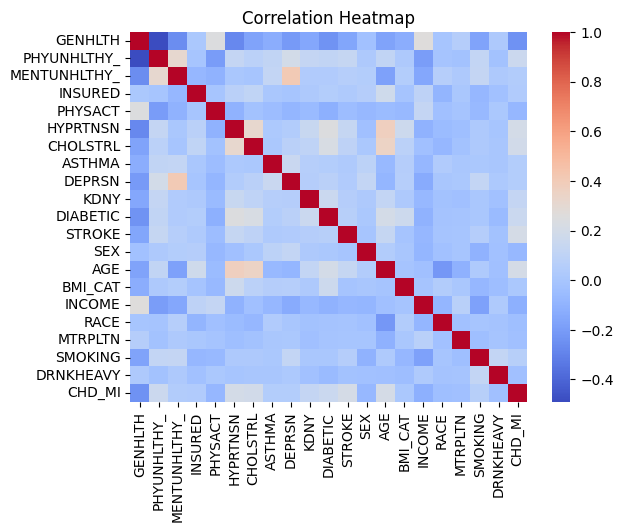

In [37]:
# Convert categorical to numerical for correlation
sns.heatmap(df_filtered.corr(), cmap='coolwarm', annot=False)
plt.title("Correlation Heatmap")
plt.show()

#### Chi-Squared Test for Categorical Features

In [38]:
from sklearn.feature_selection import chi2
from sklearn.preprocessing import LabelEncoder
from sklearn.impute import SimpleImputer
import pandas as pd

# Select categorical features and the target
cat_cols = [
    'GENHLTH', 'INSURED', 'PHYSACT', 'HYPRTNSN', 'CHOLSTRL', 'ASTHMA', 'DEPRSN', 'KDNY',
    'DIABETIC', 'STROKE', 'SEX', 'AGE', 'BMI_CAT', 'INCOME', 'RACE', 'MTRPLTN', 'SMOKING', 'DRNKHEAVY'
]
target = 'CHD_MI'

X = df_filtered[cat_cols].astype(int)
y = df_filtered[target].astype(int)

# Apply chi2 test
chi2_vals, p_vals = chi2(X, y)

# Display results
chi2_results = pd.DataFrame({
    'Feature': cat_cols,
    'Chi2': chi2_vals,
    'p-value': p_vals
}).sort_values(by='Chi2', ascending=False)

print(chi2_results)

      Feature        Chi2       p-value
9      STROKE  281.885267  2.915873e-63
11        AGE  165.692543  6.456948e-38
4    CHOLSTRL  152.214957  5.686510e-35
3    HYPRTNSN  147.810665  5.218179e-34
0     GENHLTH  141.959963  9.922834e-33
8    DIABETIC  138.234505  6.475952e-32
7        KDNY  105.280482  1.060153e-24
16    SMOKING   44.430665  2.635268e-11
2     PHYSACT   42.222268  8.146708e-11
13     INCOME   35.211150  2.958250e-09
14       RACE   18.513442  1.687103e-05
5      ASTHMA   14.679265  1.274406e-04
6      DEPRSN   13.540991  2.334091e-04
17  DRNKHEAVY    8.220103  4.142885e-03
10        SEX    5.715077  1.681983e-02
15    MTRPLTN    2.645681  1.038317e-01
1     INSURED    0.506788  4.765326e-01
12    BMI_CAT    0.255197  6.134389e-01


In [39]:
# drop INSURED, MENTUNHLTHY_
df_filtered.drop(columns=['INSURED', 'MENTUNHLTHY_', 'BMI_CAT', 'MTRPLTN'], inplace=True)

### Pipline Construction

Split data into training and testing sets

In [40]:
# train-test split
from sklearn.model_selection import train_test_split
X = df_filtered.drop(columns=['CHD_MI'])
y = df_filtered['CHD_MI']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

Data transformation (scaling and encoding)

In [41]:
# Define categorical (smoking, race) and numerical columns
categorical_cols = ['SMOKING', 'RACE']
numerical_cols = X_train.select_dtypes(include=['float64', 'int64']).columns.tolist()
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numerical_cols),
        ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_cols)
    ]
)

Data resampling to handle significant class imbalance

In [42]:
# Define resampling steps - we'll integrate these directly into the pipeline
under_sampler = RandomUnderSampler(sampling_strategy=0.33, random_state=42)
smote = SMOTE(sampling_strategy=0.5, random_state=42)

# Model Training
### Model Selection
Select models based on problem type and data characteristics
> - Decision Tree
> - Random Forest
> - KNN
> - Naive Bayes
> - AdaBoost
> - XGBoost
> - Logistic regression
> - SVM  




In [43]:
# Model Training and Evaluation for Multiple Classifiers
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score
from sklearn.model_selection import cross_val_score, StratifiedKFold
from imblearn.pipeline import make_pipeline
import pandas as pd

# Fix the sparse data issue for Naive Bayes by updating the preprocessor
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# Create a modified preprocessor that outputs dense arrays
preprocessor_dense = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numerical_cols),
        ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), categorical_cols)
    ]
)

models = {
    'Decision Tree': DecisionTreeClassifier(random_state=42),
    'Random Forest': RandomForestClassifier(random_state=42),
    'KNN': KNeighborsClassifier(),
    'Naive Bayes': GaussianNB(),
    'AdaBoost': AdaBoostClassifier(random_state=42),
    'XGBoost': XGBClassifier(use_label_encoder=False, eval_metric='logloss', random_state=42),
    'Logistic Regression': LogisticRegression(max_iter=1000, random_state=42),
    'SVM': SVC(probability=True, random_state=42)
}



### Model Training and Evaluation
Train selected models using the training set
Evaluate models using the testing set

In [44]:
results = []
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

for name, model in models.items():
    try:
        # Use dense preprocessor for Naive Bayes, regular preprocessor for others
        current_preprocessor = preprocessor_dense if name == "Naive Bayes" else preprocessor

        # Build pipeline: preprocessing + resampling + model
        # Note: imblearn make_pipeline properly handles resampling steps
        pipe = make_pipeline(current_preprocessor, under_sampler, smote, model)

        # Cross-validation
        acc = cross_val_score(pipe, X_train, y_train, cv=cv, scoring="accuracy").mean()
        prec = cross_val_score(
            pipe, X_train, y_train, cv=cv, scoring="precision", error_score="raise"
        ).mean()
        rec = cross_val_score(
            pipe, X_train, y_train, cv=cv, scoring="recall", error_score="raise"
        ).mean()
        f1 = cross_val_score(
            pipe, X_train, y_train, cv=cv, scoring="f1", error_score="raise"
        ).mean()
        roc = cross_val_score(
            pipe, X_train, y_train, cv=cv, scoring="roc_auc", error_score="raise"
        ).mean()

        results.append(
            {
                "Model": name,
                "Accuracy": acc,
                "Precision": prec,
                "Recall": rec,
                "F1-score": f1,
                "ROC-AUC": roc,
            }
        )
        print(f"✓ {name} completed successfully")

    except Exception as e:
        print(f"✗ Model {name} failed with error: {e}")
        import traceback

        traceback.print_exc()

results_df = pd.DataFrame(results)

✓ Decision Tree completed successfully
✓ Random Forest completed successfully
✓ KNN completed successfully
✓ Naive Bayes completed successfully
✓ AdaBoost completed successfully


/usr/local/lib/python3.11/dist-packages/xgboost/core.py:158: UserWarning: [15:50:26] WARNING: /workspace/src/learner.cc:740: 
Parameters: { "use_label_encoder" } are not used.

  warnings.warn(smsg, UserWarning)
/usr/local/lib/python3.11/dist-packages/xgboost/core.py:158: UserWarning: [15:50:26] WARNING: /workspace/src/learner.cc:740: 
Parameters: { "use_label_encoder" } are not used.

  warnings.warn(smsg, UserWarning)
/usr/local/lib/python3.11/dist-packages/xgboost/core.py:158: UserWarning: [15:50:26] WARNING: /workspace/src/learner.cc:740: 
Parameters: { "use_label_encoder" } are not used.

  warnings.warn(smsg, UserWarning)
/usr/local/lib/python3.11/dist-packages/xgboost/core.py:158: UserWarning: [15:50:26] WARNING: /workspace/src/learner.cc:740: 
Parameters: { "use_label_encoder" } are not used.

  warnings.warn(smsg, UserWarning)
/usr/local/lib/python3.11/dist-packages/xgboost/core.py:158: UserWarning: [15:50:26] WARNING: /workspace/src/learner.cc:740: 
Parameters: { "use_label_e

✓ XGBoost completed successfully
✓ Logistic Regression completed successfully
✓ SVM completed successfully


### Hyperparameter Tuning
Use techniques like Grid Search or Random Search to optimize model parameters

In [45]:
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import make_scorer, f1_score

# Define parameter grids for each model
param_grids = {
    'Decision Tree': {
        'decisiontreeclassifier__max_depth': [3, 5, 10, None],
        'decisiontreeclassifier__min_samples_split': [2, 5, 10],
        'decisiontreeclassifier__min_samples_leaf': [1, 2, 4]
    },
    'Random Forest': {
        'randomforestclassifier__n_estimators': [50, 100, 200],
        'randomforestclassifier__max_depth': [3, 5, 10, None],
        'randomforestclassifier__min_samples_split': [2, 5, 10]
    },
    'AdaBoost': {
        'adaboostclassifier__n_estimators': [50, 100, 200],
        'adaboostclassifier__learning_rate': [0.5, 1.0, 1.5],
        'adaboostclassifier__algorithm': ['SAMME', 'SAMME.R']
    },
    'XGBoost': {
        'xgbclassifier__n_estimators': [50, 100, 200],
        'xgbclassifier__max_depth': [3, 5, 7],
        'xgbclassifier__learning_rate': [0.01, 0.1, 0.2]
    }
}

# Perform hyperparameter tuning for each model
tuned_results = []
best_models = {}

for name, model in models.items():
    print(f"Tuning {name}...")

    try:
        # Create pipeline
        pipe = make_pipeline(preprocessor, under_sampler, smote, model)

        # Get parameter grid for this model
        param_grid = param_grids[name]

        # Use F1-score as the scoring metric (better for imbalanced data)
        grid_search = GridSearchCV(
            pipe,
            param_grid,
            cv=3,  # Reduced CV folds for faster execution
            scoring='f1',
            n_jobs=-1,
            verbose=1
        )

        # Fit grid search
        grid_search.fit(X_train, y_train)

        # Store best model
        best_models[name] = grid_search.best_estimator_

        # Get best cross-validation scores
        best_score = grid_search.best_score_
        best_params = grid_search.best_params_

        tuned_results.append({
            'Model': name,
            'Best_F1_CV': best_score,
            'Best_Parameters': best_params
        })

        print(f"✓ {name} tuning completed")
        print(f"  Best F1-score: {best_score:.4f}")
        print(f"  Best parameters: {best_params}")
        print()

    except Exception as e:
        print(f"✗ {name} tuning failed with error: {e}")

# Display tuning results
tuned_results_df = pd.DataFrame(tuned_results)
print("\n" + "="*80)
print("HYPERPARAMETER TUNING RESULTS")
print("="*80)
if len(tuned_results_df) > 0:
    tuned_results_df_sorted = tuned_results_df.sort_values(by='Best_F1_CV', ascending=False)
    for idx, row in tuned_results_df_sorted.iterrows():
        print(f"Model: {row['Model']}")
        print(f"Best F1-score: {row['Best_F1_CV']:.4f}")
        print(f"Best Parameters: {row['Best_Parameters']}")
        print("-" * 40)

Tuning Decision Tree...
Fitting 3 folds for each of 36 candidates, totalling 108 fits
✓ Decision Tree tuning completed
  Best F1-score: 0.2509
  Best parameters: {'decisiontreeclassifier__max_depth': 3, 'decisiontreeclassifier__min_samples_leaf': 1, 'decisiontreeclassifier__min_samples_split': 2}

Tuning Random Forest...
Fitting 3 folds for each of 36 candidates, totalling 108 fits
✓ Random Forest tuning completed
  Best F1-score: 0.2326
  Best parameters: {'randomforestclassifier__max_depth': None, 'randomforestclassifier__min_samples_split': 2, 'randomforestclassifier__n_estimators': 200}

Tuning KNN...
✗ KNN tuning failed with error: 'KNN'
Tuning Naive Bayes...
✗ Naive Bayes tuning failed with error: 'Naive Bayes'
Tuning AdaBoost...
Fitting 3 folds for each of 18 candidates, totalling 54 fits


/usr/local/lib/python3.11/dist-packages/sklearn/model_selection/_validation.py:528: FitFailedWarning: 
27 fits failed out of a total of 54.
The score on these train-test partitions for these parameters will be set to nan.
If these failures are not expected, you can try to debug them by setting error_score='raise'.

Below are more details about the failures:
--------------------------------------------------------------------------------
27 fits failed with the following error:
Traceback (most recent call last):
  File "/usr/local/lib/python3.11/dist-packages/sklearn/model_selection/_validation.py", line 866, in _fit_and_score
    estimator.fit(X_train, y_train, **fit_params)
  File "/usr/local/lib/python3.11/dist-packages/sklearn/base.py", line 1389, in wrapper
    return fit_method(estimator, *args, **kwargs)
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/usr/local/lib/python3.11/dist-packages/imblearn/pipeline.py", line 526, in fit
    self._final_estimator.fit(Xt, yt, **

✓ AdaBoost tuning completed
  Best F1-score: 0.2565
  Best parameters: {'adaboostclassifier__algorithm': 'SAMME', 'adaboostclassifier__learning_rate': 1.0, 'adaboostclassifier__n_estimators': 50}

Tuning XGBoost...
Fitting 3 folds for each of 27 candidates, totalling 81 fits
✓ XGBoost tuning completed
  Best F1-score: 0.2402
  Best parameters: {'xgbclassifier__learning_rate': 0.1, 'xgbclassifier__max_depth': 3, 'xgbclassifier__n_estimators': 50}

Tuning Logistic Regression...
✗ Logistic Regression tuning failed with error: 'Logistic Regression'
Tuning SVM...
✗ SVM tuning failed with error: 'SVM'

HYPERPARAMETER TUNING RESULTS
Model: AdaBoost
Best F1-score: 0.2565
Best Parameters: {'adaboostclassifier__algorithm': 'SAMME', 'adaboostclassifier__learning_rate': 1.0, 'adaboostclassifier__n_estimators': 50}
----------------------------------------
Model: Decision Tree
Best F1-score: 0.2509
Best Parameters: {'decisiontreeclassifier__max_depth': 3, 'decisiontreeclassifier__min_samples_leaf': 

/usr/local/lib/python3.11/dist-packages/xgboost/core.py:158: UserWarning: [15:51:37] WARNING: /workspace/src/learner.cc:740: 
Parameters: { "use_label_encoder" } are not used.

  warnings.warn(smsg, UserWarning)


In [46]:
# Evaluate tuned models on test set
print("\n" + "=" * 100)
print("DETAILED EVALUATION OF TUNED MODELS (After Hyperparameter Tuning)")
print("=" * 100)

tuned_test_results = []

for name, best_model in best_models.items():
    try:
        # Predict on test set using the best model
        y_pred = best_model.predict(X_test)
        y_pred_proba = best_model.predict_proba(X_test)[:, 1]

        # Calculate metrics
        test_acc = accuracy_score(y_test, y_pred)
        test_prec = precision_score(y_test, y_pred)
        test_rec = recall_score(y_test, y_pred)
        test_f1 = f1_score(y_test, y_pred)
        test_roc = roc_auc_score(y_test, y_pred_proba)

        tuned_test_results.append({
            'Model': name,
            'Tuned_Test_Accuracy': test_acc,
            'Tuned_Test_Precision': test_prec,
            'Tuned_Test_Recall': test_rec,
            'Tuned_Test_F1': test_f1,
            'Tuned_Test_ROC_AUC': test_roc
        })

        print(f"\n{name} (Tuned) - Test Set Performance:")
        print(f"  Accuracy:  {test_acc:.4f}")
        print(f"  Precision: {test_prec:.4f}")
        print(f"  Recall:    {test_rec:.4f}")
        print(f"  F1-score:  {test_f1:.4f}")
        print(f"  ROC-AUC:   {test_roc:.4f}")

        # Confusion Matrix for tuned model
        cm = confusion_matrix(y_test, y_pred)
        plt.figure(figsize=(6, 4))
        sns.heatmap(cm, annot=True, fmt='d', cmap='Greens',
                   xticklabels=['No CHD/MI', 'CHD/MI'],
                   yticklabels=['No CHD/MI', 'CHD/MI'])
        plt.title(f'{name} (Tuned) - Confusion Matrix (Test Set)')
        plt.ylabel('True Label')
        plt.xlabel('Predicted Label')
        plt.show()

    except Exception as e:
        print(f"\n✗ {name} (tuned) evaluation failed: {e}")

# Create summary DataFrame for tuned models
tuned_test_df = pd.DataFrame(tuned_test_results)
if len(tuned_test_df) > 0:
    tuned_test_df_sorted = tuned_test_df.sort_values(by='Tuned_Test_ROC_AUC', ascending=False)
    print("\n" + "=" * 80)
    print("TUNED MODELS - TEST SET PERFORMANCE SUMMARY")
    print("=" * 80)
    for col in ['Tuned_Test_Accuracy', 'Tuned_Test_Precision', 'Tuned_Test_Recall', 'Tuned_Test_F1', 'Tuned_Test_ROC_AUC']:
        tuned_test_df_sorted[col] = tuned_test_df_sorted[col].apply(lambda x: f"{x:.4f}")
    print(tuned_test_df_sorted.to_string(index=False))
    print("\n" + "=" * 80)


DETAILED EVALUATION OF TUNED MODELS (After Hyperparameter Tuning)

Decision Tree (Tuned) - Test Set Performance:
  Accuracy:  0.8165
  Precision: 0.2050
  Recall:    0.2808
  F1-score:  0.2370
  ROC-AUC:   0.6343

✗ Decision Tree (tuned) evaluation failed: name 'confusion_matrix' is not defined

Random Forest (Tuned) - Test Set Performance:
  Accuracy:  0.8158
  Precision: 0.2153
  Recall:    0.3082
  F1-score:  0.2535
  ROC-AUC:   0.6209

✗ Random Forest (tuned) evaluation failed: name 'confusion_matrix' is not defined

AdaBoost (Tuned) - Test Set Performance:
  Accuracy:  0.8145
  Precision: 0.2049
  Recall:    0.2877
  F1-score:  0.2393
  ROC-AUC:   0.6609

✗ AdaBoost (tuned) evaluation failed: name 'confusion_matrix' is not defined

XGBoost (Tuned) - Test Set Performance:
  Accuracy:  0.8325
  Precision: 0.2254
  Recall:    0.2671
  F1-score:  0.2445
  ROC-AUC:   0.6549

✗ XGBoost (tuned) evaluation failed: name 'confusion_matrix' is not defined

TUNED MODELS - TEST SET PERFORMANC

In [47]:
# Compare original vs tuned models
print("\n" + "=" * 100)
print("COMPARISON: ORIGINAL vs TUNED MODELS")
print("=" * 100)

if len(original_test_df) > 0 and len(tuned_test_df) > 0:
    # Merge the dataframes for comparison
    comparison_df = pd.merge(original_test_df, tuned_test_df, on='Model', how='inner')

    # Calculate improvements
    comparison_df['Accuracy_Improvement'] = comparison_df['Tuned_Test_Accuracy'] - comparison_df['Test_Accuracy']
    comparison_df['Precision_Improvement'] = comparison_df['Tuned_Test_Precision'] - comparison_df['Test_Precision']
    comparison_df['Recall_Improvement'] = comparison_df['Tuned_Test_Recall'] - comparison_df['Test_Recall']
    comparison_df['F1_Improvement'] = comparison_df['Tuned_Test_F1'] - comparison_df['Test_F1']
    comparison_df['ROC_AUC_Improvement'] = comparison_df['Tuned_Test_ROC_AUC'] - comparison_df['Test_ROC_AUC']

    print("\nMODEL PERFORMANCE IMPROVEMENTS (Tuned - Original):")
    print("-" * 60)
    for idx, row in comparison_df.iterrows():
        print(f"\n{row['Model']}:")
        print(f"  Accuracy:  {row['Accuracy_Improvement']:+.4f} ({row['Test_Accuracy']:.4f} → {row['Tuned_Test_Accuracy']:.4f})")
        print(f"  Precision: {row['Precision_Improvement']:+.4f} ({row['Test_Precision']:.4f} → {row['Tuned_Test_Precision']:.4f})")
        print(f"  Recall:    {row['Recall_Improvement']:+.4f} ({row['Test_Recall']:.4f} → {row['Tuned_Test_Recall']:.4f})")
        print(f"  F1-score:  {row['F1_Improvement']:+.4f} ({row['Test_F1']:.4f} → {row['Tuned_Test_F1']:.4f})")
        print(f"  ROC-AUC:   {row['ROC_AUC_Improvement']:+.4f} ({row['Test_ROC_AUC']:.4f} → {row['Tuned_Test_ROC_AUC']:.4f})")

    # Visualization of improvements
    plt.figure(figsize=(15, 10))

    # Plot 1: Original vs Tuned Performance
    metrics = ['Accuracy', 'Precision', 'Recall', 'F1', 'ROC_AUC']
    x = np.arange(len(comparison_df))
    width = 0.35

    for i, metric in enumerate(metrics):
        plt.subplot(2, 3, i+1)
        original_vals = comparison_df[f'Test_{metric}'].values
        tuned_vals = comparison_df[f'Tuned_Test_{metric}'].values

        plt.bar(x - width/2, original_vals, width, label='Original', alpha=0.7)
        plt.bar(x + width/2, tuned_vals, width, label='Tuned', alpha=0.7)

        plt.xlabel('Models')
        plt.ylabel(metric)
        plt.title(f'{metric}: Original vs Tuned')
        plt.xticks(x, comparison_df['Model'], rotation=45)
        plt.legend()
        plt.grid(True, alpha=0.3)

    plt.tight_layout()
    plt.show()

    # Summary statistics
    print("\n" + "=" * 80)
    print("IMPROVEMENT SUMMARY STATISTICS:")
    print("=" * 80)
    improvement_cols = ['Accuracy_Improvement', 'Precision_Improvement', 'Recall_Improvement', 'F1_Improvement', 'ROC_AUC_Improvement']
    improvement_summary = comparison_df[improvement_cols].describe()
    print(improvement_summary.round(4))

    # Best overall model
    best_original = original_test_df.loc[original_test_df['Test_ROC_AUC'].idxmax()]
    best_tuned = tuned_test_df.loc[tuned_test_df['Tuned_Test_ROC_AUC'].idxmax()]

    print("\n" + "=" * 80)
    print("BEST MODELS:")
    print("=" * 80)
    print(f"Best Original Model: {best_original['Model']} (ROC-AUC: {best_original['Test_ROC_AUC']:.4f})")
    print(f"Best Tuned Model: {best_tuned['Model']} (ROC-AUC: {best_tuned['Tuned_Test_ROC_AUC']:.4f})")

    overall_improvement = best_tuned['Tuned_Test_ROC_AUC'] - best_original['Test_ROC_AUC']
    print(f"Overall Best Performance Improvement: {overall_improvement:+.4f}")
    print("=" * 80)

else:
    print("Cannot perform comparison - missing evaluation results.")


COMPARISON: ORIGINAL vs TUNED MODELS


NameError: name 'original_test_df' is not defined

### Model Evaluation
Evaluate models using metrics like accuracy, precision, recall, F1-score, and ROC-AUC

In [ ]:
if len(results_df) > 0:
    # Sort by ROC-AUC score
    results_df_sorted = results_df.sort_values(by="ROC-AUC", ascending=False)

    print("\\n" + "=" * 80)
    print("MODEL PERFORMANCE COMPARISON (sorted by ROC-AUC)")
    print("=" * 80)

    # Format the display with better precision
    for col in ["Accuracy", "Precision", "Recall", "F1-score", "ROC-AUC"]:
        results_df_sorted[col] = results_df_sorted[col].apply(lambda x: f"{x:.4f}")

    print(results_df_sorted.to_string(index=False))

    print("\\n" + "=" * 80)
    print("SUMMARY:")
    print(f"Best performing model: {results_df_sorted.iloc[0]['Model']}")
    print(f"Highest ROC-AUC: {results_df_sorted.iloc[0]['ROC-AUC']}")
    print("=" * 80)
else:
    print("No models completed successfully. Please check the errors above.")



In [ ]:
# Comprehensive evaluation of original models
from sklearn.metrics import classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

print("\n" + "=" * 100)
print("DETAILED EVALUATION OF ORIGINAL MODELS (Before Hyperparameter Tuning)")
print("=" * 100)

# Evaluate each original model on test set
original_test_results = []

for name, model in models.items():
    try:
        # Use appropriate preprocessor for each model
        current_preprocessor = preprocessor_dense if name == 'Naive Bayes' else preprocessor

        # Build pipeline
        pipe = make_pipeline(current_preprocessor, under_sampler, smote, model)

        # Fit on training data
        pipe.fit(X_train, y_train)

        # Predict on test set
        y_pred = pipe.predict(X_test)
        y_pred_proba = pipe.predict_proba(X_test)[:, 1]

        # Calculate metrics
        test_acc = accuracy_score(y_test, y_pred)
        test_prec = precision_score(y_test, y_pred)
        test_rec = recall_score(y_test, y_pred)
        test_f1 = f1_score(y_test, y_pred)
        test_roc = roc_auc_score(y_test, y_pred_proba)

        original_test_results.append({
            'Model': name,
            'Test_Accuracy': test_acc,
            'Test_Precision': test_prec,
            'Test_Recall': test_rec,
            'Test_F1': test_f1,
            'Test_ROC_AUC': test_roc
        })

        print(f"\n{name} - Test Set Performance:")
        print(f"  Accuracy:  {test_acc:.4f}")
        print(f"  Precision: {test_prec:.4f}")
        print(f"  Recall:    {test_rec:.4f}")
        print(f"  F1-score:  {test_f1:.4f}")
        print(f"  ROC-AUC:   {test_roc:.4f}")

        # Confusion Matrix
        cm = confusion_matrix(y_test, y_pred)
        plt.figure(figsize=(6, 4))
        sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                   xticklabels=['No CHD/MI', 'CHD/MI'],
                   yticklabels=['No CHD/MI', 'CHD/MI'])
        plt.title(f'{name} - Confusion Matrix (Test Set)')
        plt.ylabel('True Label')
        plt.xlabel('Predicted Label')
        plt.show()

    except Exception as e:
        print(f"\n✗ {name} evaluation failed: {e}")

# Create summary DataFrame for original models
original_test_df = pd.DataFrame(original_test_results)
if len(original_test_df) > 0:
    original_test_df_sorted = original_test_df.sort_values(by='Test_ROC_AUC', ascending=False)
    print("\n" + "=" * 80)
    print("ORIGINAL MODELS - TEST SET PERFORMANCE SUMMARY")
    print("=" * 80)
    for col in ['Test_Accuracy', 'Test_Precision', 'Test_Recall', 'Test_F1', 'Test_ROC_AUC']:
        original_test_df_sorted[col] = original_test_df_sorted[col].apply(lambda x: f"{x:.4f}")
    print(original_test_df_sorted.to_string(index=False))
    print("\n" + "=" * 80)


### Model Comparison
Compare model performance using evaluation metrics
### Post-hoc Analysis
This step involves analyzing the model's performance and understanding feature importance.

TODO:
> Continue with the pipeline construction. Consider:
> - Decision Tree
> - Random Forest
> - KNN
> - Naive Bayes
> - AdaBoost
> - XGBoost
> - Logistic regression
> - SVM  
  
> Evaluate models using accuracy, precision, recall, F1-score, and ROC-AUC.  
  
> Make sure to use cross-validation for robust evaluation.  
  
> We can explore post-hoc analysis to understand feature importance and model performance together.

## 🚀 Google Colab Setup

Run the cells below to set up your environment in Google Colab.

In [ ]:
# Google Colab Setup Cell - Run this first!
import sys
import os

# Check if running in Colab
try:
    import google.colab
    IN_COLAB = True
    print("🎉 Running in Google Colab!")
except ImportError:
    IN_COLAB = False
    print("💻 Running locally")

if IN_COLAB:
    # Mount Google Drive to access your data
    from google.colab import drive
    drive.mount('/content/drive')
    print("✅ Google Drive mounted successfully!")

    # Install required packages
    print("\n📦 Installing required packages...")
    !pip install xgboost imbalanced-learn -q
    print("✅ Packages installed!")

    # Set data path for Colab
    # Update this path to match where you uploaded your dataset in Google Drive
    DATA_PATH = "/content/drive/MyDrive/BRFSS_2023.csv"
    print(f"📊 Data path set to: {DATA_PATH}")
    print("\n⚠️  Make sure to upload BRFSS_2023.csv to your Google Drive root folder!")

else:
    # Local development path
    DATA_PATH = "../data/BRFSS_2023.csv"
    print(f"📊 Local data path: {DATA_PATH}")

### 📁 Data Upload Instructions for Colab

If you're running this in Google Colab:

1. **Download the dataset** from [BRFSS 2023 Data](https://www.cdc.gov/brfss/annual_data/annual_2023.html)
2. **Upload to Google Drive**: Save `BRFSS_2023.csv` to your Google Drive root folder
3. **Alternative**: Use the file upload widget below to upload directly to Colab (temporary)

```python
# Alternative: Upload directly to Colab (runs faster but temporary)
from google.colab import files
uploaded = files.upload()
DATA_PATH = list(uploaded.keys())[0]
```